## Лабораторная работа №1 | Вариант 5

Выполнил: Мышакин Михаил, М8О-312БВ-24

### 1. Numpy

In [1]:
import numpy as np

rng = np.random.default_rng(42)
np.set_printoptions(precision=4, suppress=True)


1. Создайте единичную матрицу размером 3х3

In [2]:
identity = np.eye(3, dtype=int)
print(identity)


[[1 0 0]
 [0 1 0]
 [0 0 1]]


2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [3]:
rgba_dtype = np.dtype([
    ('R', np.uint8), ('G', np.uint8),
    ('B', np.uint8), ('A', np.uint8),
])
pixel = np.array([(255, 128, 64, 255)], dtype=rgba_dtype)
print('Тип:', rgba_dtype)
print('Пиксель:', pixel)
print('Размер одного пикселя:', rgba_dtype.itemsize, 'байта')


Тип: [('R', 'u1'), ('G', 'u1'), ('B', 'u1'), ('A', 'u1')]
Пиксель: [(255, 128, 64, 255)]
Размер одного пикселя: 4 байта


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [4]:
import warnings

previous_settings = np.seterr(all='ignore')
try:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        print(np.array([0.0, 1.0]) / 0.0)
finally:

    np.seterr(**previous_settings)


[nan inf]


4. Создайте случайный вектор размера 10 и отсортируйте его

In [5]:
vector = rng.random(10)
print('Исходный вектор:', vector)
vector.sort()
print('Отсортированный:', vector)


Исходный вектор: [0.774  0.4389 0.8586 0.6974 0.0942 0.9756 0.7611 0.7861 0.1281 0.4504]
Отсортированный: [0.0942 0.1281 0.4389 0.4504 0.6974 0.7611 0.774  0.7861 0.8586 0.9756]


5. Создайте read-only массив(неизменяемый)

In [6]:
readonly_array = np.arange(5)
readonly_array.setflags(write=False)
print('Массив:', readonly_array)
print('Разрешена запись:', readonly_array.flags.writeable)

try:
    readonly_array[0] = 100
except ValueError as error:
    print('Попытка изменения отклонена:', error)


Массив: [0 1 2 3 4]
Разрешена запись: False
Попытка изменения отклонена: assignment destination is read-only


6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [7]:
cartesian = rng.uniform(-1, 1, size=(10, 2))
radius = np.hypot(cartesian[:, 0], cartesian[:, 1])
angle = np.arctan2(cartesian[:, 1], cartesian[:, 0])
polar = np.column_stack((radius, angle))

print('Декартовы координаты [x, y]:')
print(cartesian)
print('Полярные координаты [r, угол в радианах]:')
print(polar)


Декартовы координаты [x, y]:
[[-0.2584  0.8535]
 [ 0.2877  0.6455]
 [-0.1132 -0.5455]
 [ 0.1092 -0.8724]
 [ 0.6553  0.2633]
 [ 0.5162 -0.2909]
 [ 0.9414  0.7862]
 [ 0.5568 -0.6107]
 [-0.0666 -0.9124]
 [-0.6914  0.3661]]
Полярные координаты [r, угол в радианах]:
[[ 0.8918  1.8648]
 [ 0.7067  1.1515]
 [ 0.5571 -1.7754]
 [ 0.8792 -1.4463]
 [ 0.7062  0.3821]
 [ 0.5925 -0.5133]
 [ 1.2265  0.6958]
 [ 0.8264 -0.8316]
 [ 0.9148 -1.6436]
 [ 0.7824  2.6546]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [8]:
axis = np.linspace(0, 1, 5)
grid_x, grid_y = np.meshgrid(axis, axis)
coordinates = np.empty(grid_x.shape, dtype=[('x', np.float64), ('y', np.float64)])
coordinates['x'] = grid_x
coordinates['y'] = grid_y
print(coordinates)


[[(0.  , 0.  ) (0.25, 0.  ) (0.5 , 0.  ) (0.75, 0.  ) (1.  , 0.  )]
 [(0.  , 0.25) (0.25, 0.25) (0.5 , 0.25) (0.75, 0.25) (1.  , 0.25)]
 [(0.  , 0.5 ) (0.25, 0.5 ) (0.5 , 0.5 ) (0.75, 0.5 ) (1.  , 0.5 )]
 [(0.  , 0.75) (0.25, 0.75) (0.5 , 0.75) (0.75, 0.75) (1.  , 0.75)]
 [(0.  , 1.  ) (0.25, 1.  ) (0.5 , 1.  ) (0.75, 1.  ) (1.  , 1.  )]]


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [9]:
x = rng.normal(size=5)
y = rng.normal(size=5)
differences = x[:, np.newaxis] - y[np.newaxis, :]
if np.any(differences == 0):
    raise ValueError('Матрица Коши не определена при x[i] = y[j].')
cauchy_matrix = 1.0 / differences
print('x:', x)
print('y:', y)
print('Матрица Коши:')
print(cauchy_matrix)


x: [ 2.1416 -0.4064 -0.5122 -0.8138  0.616 ]
y: [ 1.129  -0.1139 -0.8402 -0.8245  0.6506]
Матрица Коши:
[[  0.9875   0.4433   0.3354   0.3371   0.6707]
 [ -0.6513  -3.4192   2.3055   2.392   -0.9461]
 [ -0.6093  -2.5107   3.0496   3.2027  -0.86  ]
 [ -0.5147  -1.4289  37.9021  93.3839  -0.6829]
 [ -1.9493   1.37     0.6867   0.6942 -28.8906]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [10]:
numbers = np.array([1.9, -2.7, 3.0, 0.5, -0.5], dtype=np.float32)
original_address = numbers.ctypes.data
print('До преобразования:', numbers, numbers.dtype)

integer_view = numbers.view(np.int32)

for i in range(numbers.size):
    integer_view[i] = int(numbers[i])
numbers = integer_view

print('После преобразования:', numbers, numbers.dtype)
print('Адрес буфера сохранился:', numbers.ctypes.data == original_address)


До преобразования: [ 1.9 -2.7  3.   0.5 -0.5] float32
После преобразования: [ 1 -2  3  0  0] int32
Адрес буфера сохранился: True


10. Как случайно заменить p элементов в 2D массиве?

In [11]:
matrix = rng.integers(0, 10, size=(4, 5))
p = 5
print('До замены:')
print(matrix)

selected_indices = rng.choice(matrix.size, size=p, replace=False)
matrix.flat[selected_indices] = -1
print('После замены пяти случайных элементов на -1:')
print(matrix)
print('Число замененных элементов:', np.count_nonzero(matrix == -1))


До замены:
[[9 4 1 8 6]
 [7 0 3 7 8]
 [4 8 8 3 8]
 [2 2 6 6 1]]
После замены пяти случайных элементов на -1:
[[-1  4  1 -1  6]
 [ 7  0  3  7  8]
 [ 4  8  8 -1 -1]
 [-1  2  6  6  1]]
Число замененных элементов: 5


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [12]:
import pandas as pd
from IPython.display import display

pd.set_option('display.precision', 2)


In [13]:
passengers = pd.read_csv('data.csv')
display(passengers.head())
print('Размер таблицы:', passengers.shape)
print('Пропущено возрастов:', passengers['Age'].isna().sum())


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.05,NaN,S


Размер таблицы: (891, 12)
Пропущено возрастов: 177


1. Узнайте сколько было на борту человек

In [14]:
print('Пассажиров в предоставленном датасете:', len(passengers))


Пассажиров в предоставленном датасете: 891


2. Какой медианный и средний возраста пассажиров

In [15]:
print(f"Медианный возраст: {passengers['Age'].median():.2f} года")
print(f"Средний возраст: {passengers['Age'].mean():.2f} года")
print('Записей с известным возрастом:', passengers['Age'].count())


Медианный возраст: 28.00 года
Средний возраст: 29.70 года
Записей с известным возрастом: 714


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [16]:
known_age = passengers.dropna(subset=['Age']).copy()
known_age['Возрастная группа'] = np.where(
    known_age['Age'] < 16, 'Дети (<16)', 'Взрослые (≥16)'
)
age_survival = known_age.groupby('Возрастная группа')['Survived'].agg(
    Пассажиров='size', Выживших='sum', Доля='mean'
).reindex(['Дети (<16)', 'Взрослые (≥16)'])
age_survival['Выживаемость, %'] = age_survival.pop('Доля') * 100
display(age_survival)
print('Пассажиров без возраста, не вошедших в сравнение:',
      passengers['Age'].isna().sum())


,Пассажиров,Выживших,"Выживаемость, %"
Возрастная группа,,,
Дети (<16),83,49,59.04
Взрослые (≥16),631,241,38.19


Пассажиров без возраста, не вошедших в сравнение: 177


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [17]:
sex_survival = passengers.groupby('Sex')['Survived'].agg(
    Пассажиров='size', Выживших='sum', Доля='mean'
).rename(index={'female': 'Женщины', 'male': 'Мужчины'})
sex_survival['Выживаемость, %'] = sex_survival.pop('Доля') * 100
display(sex_survival)

demographic_data = known_age.copy()
demographic_data['Группа'] = np.where(
    demographic_data['Age'] < 16,
    'Дети (<16)',
    np.where(demographic_data['Sex'] == 'female',
             'Женщины (≥16)', 'Мужчины (≥16)'),
)
demographic_survival = demographic_data.groupby('Группа')['Survived'].agg(
    Пассажиров='size', Выживших='sum', Доля='mean'
).reindex(['Мужчины (≥16)', 'Женщины (≥16)', 'Дети (<16)'])
demographic_survival['Выживаемость, %'] = demographic_survival.pop('Доля') * 100
display(demographic_survival)

print('Женщины и дети выживали чаще взрослых мужчин.')
print('Порядок посадки в шлюпки по этим данным проверить нельзя.')


,Пассажиров,Выживших,"Выживаемость, %"
Sex,,,
Женщины,314,233,74.20
Мужчины,577,109,18.89


,Пассажиров,Выживших,"Выживаемость, %"
Группа,,,
Мужчины (≥16),413,72,17.43
Женщины (≥16),218,169,77.52
Дети (<16),83,49,59.04


Женщины и дети выживали чаще взрослых мужчин.
Порядок посадки в шлюпки по этим данным проверить нельзя.


5. Зависит ли выживаемость от класса обслуживания?

In [18]:
class_survival = passengers.groupby('Pclass')['Survived'].agg(
    Пассажиров='size', Выживших='sum', Доля='mean'
)
class_survival['Выживаемость, %'] = class_survival.pop('Доля') * 100
display(class_survival)
print('Выживаемость в выборке выше в первом классе и ниже в третьем.')


,Пассажиров,Выживших,"Выживаемость, %"
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


Выживаемость в выборке выше в первом классе и ниже в третьем.


6. Посчитайте средний возраст умерших женщин и мужчин

In [19]:
deceased_age = passengers.loc[passengers['Survived'] == 0].groupby('Sex')['Age'].agg(
    Всего_погибших='size', Известный_возраст='count', Средний_возраст='mean'
).rename(index={'female': 'Женщины', 'male': 'Мужчины'})
display(deceased_age)


,Всего_погибших,Известный_возраст,Средний_возраст
Sex,,,
Женщины,81,64,25.05
Мужчины,468,360,31.62


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [20]:
has_relatives = (passengers['SibSp'] + passengers['Parch']) > 0
family_data = passengers.assign(
    Группа=np.where(has_relatives, 'Есть родственники', 'Одиночки')
)
family_survival = family_data.groupby('Группа')['Survived'].agg(
    Пассажиров='size', Выживших='sum', Доля='mean'
).reindex(['Есть родственники', 'Одиночки'])
family_survival['Выживаемость, %'] = family_survival.pop('Доля') * 100
display(family_survival)
difference = (family_survival.loc['Есть родственники', 'Выживаемость, %']
              - family_survival.loc['Одиночки', 'Выживаемость, %'])
print(f'У пассажиров с родственниками выживаемость выше на {difference:.2f} п.п.')


,Пассажиров,Выживших,"Выживаемость, %"
Группа,,,
Есть родственники,354,179,50.56
Одиночки,537,163,30.35


У пассажиров с родственниками выживаемость выше на 20.21 п.п.


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [21]:
fare_summary = passengers.groupby('Survived')['Fare'].agg(
    Пассажиров='size', Средняя_цена='mean'
).rename(index={0: 'Погибли', 1: 'Выжили'})
display(fare_summary)
difference = (fare_summary.loc['Выжили', 'Средняя_цена']
              - fare_summary.loc['Погибли', 'Средняя_цена'])
print(f'У выживших средняя цена билета выше на {difference:.2f} денежной единицы.')


,Пассажиров,Средняя_цена
Survived,,
Погибли,549,22.12
Выжили,342,48.40


У выживших средняя цена билета выше на 26.28 денежной единицы.


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [22]:
second_class_survivors = passengers.loc[
    (passengers['Survived'] == 1) & (passengers['Pclass'] == 2), 'Age'
]
print(f'Минимальный возраст: {second_class_survivors.min():.2f} года')
print(f'Максимальный возраст: {second_class_survivors.max():.2f} года')
print('Известных возрастов:', second_class_survivors.count())
print('Пропусков возраста:', second_class_survivors.isna().sum())


Минимальный возраст: 0.67 года
Максимальный возраст: 62.00 года
Известных возрастов: 83
Пропусков возраста: 4


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [23]:
adult_men = passengers.loc[
    (passengers['Sex'] == 'male') & (passengers['Age'] >= 18)
].copy()
adult_men['Группа'] = np.where(
    adult_men['Age'] <= 35, '18–35 лет', 'Старше 35 лет'
)
men_survival = adult_men.groupby('Группа')['Survived'].agg(
    Пассажиров='size', Выживших='sum', Доля='mean'
).reindex(['18–35 лет', 'Старше 35 лет'])
men_survival['Выживаемость, %'] = men_survival.pop('Доля') * 100
display(men_survival)

young_rate = men_survival.loc['18–35 лет', 'Выживаемость, %']
older_rate = men_survival.loc['Старше 35 лет', 'Выживаемость, %']
print(f'Разница (молодые минус старшие): {young_rate - older_rate:.2f} п.п.')
if young_rate > older_rate:
    print('Для выбранной границы гипотеза описательно поддерживается данными.')
else:
    print('Для выбранной границы гипотеза не подтверждается данными:')
    print('у молодых мужчин доля выживших не выше, чем у более взрослых.')


,Пассажиров,Выживших,"Выживаемость, %"
Группа,,,
18–35 лет,251,44,17.53
Старше 35 лет,144,26,18.06


Разница (молодые минус старшие): -0.53 п.п.
Для выбранной границы гипотеза не подтверждается данными:
у молодых мужчин доля выживших не выше, чем у более взрослых.


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

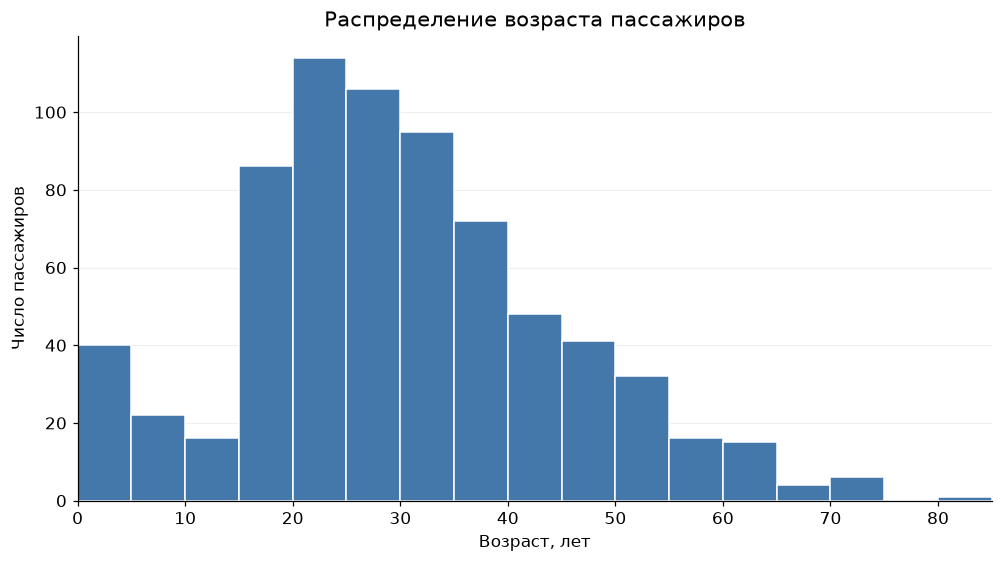

In [24]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
})
age_bins = np.arange(0, 86, 5)
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
ax.hist(passengers['Age'].dropna(), bins=age_bins,
        color='#4477AA', edgecolor='white')
ax.set(title='Распределение возраста пассажиров',
       xlabel='Возраст, лет', ylabel='Число пассажиров')
ax.set_xlim(0, 85)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
plt.show()


2. Постройте гистограммы распределения цен для пассажиров разных классов

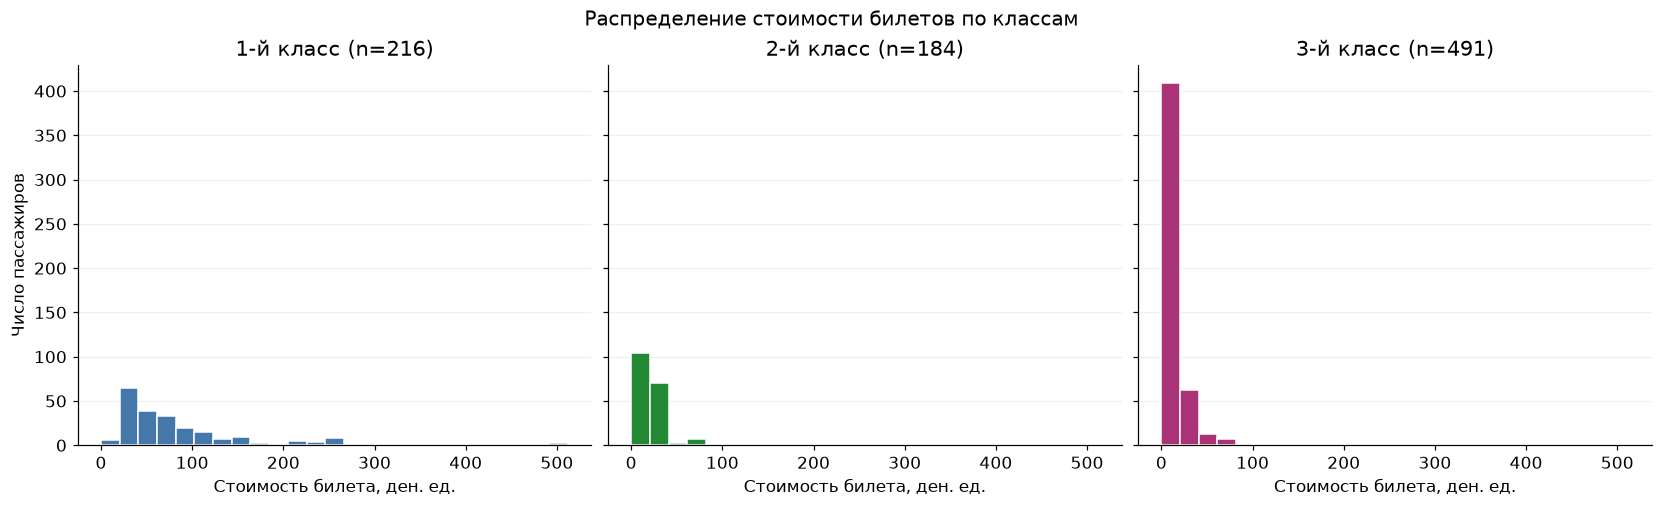

In [25]:
fare_bins = np.linspace(0, passengers['Fare'].max(), 26)
class_colors = ['#4477AA', '#228833', '#AA3377']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5),
                         sharex=True, sharey=True, layout='constrained')
for ax, passenger_class, color in zip(axes, [1, 2, 3], class_colors):
    fares = passengers.loc[passengers['Pclass'] == passenger_class, 'Fare'].dropna()
    ax.hist(fares, bins=fare_bins, color=color, edgecolor='white')
    ax.set(title=f'{passenger_class}-й класс (n={len(fares)})',
           xlabel='Стоимость билета, ден. ед.')
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
axes[0].set_ylabel('Число пассажиров')
fig.suptitle('Распределение стоимости билетов по классам')
plt.show()


3. Постройте зависимость цены от возраста пассажира

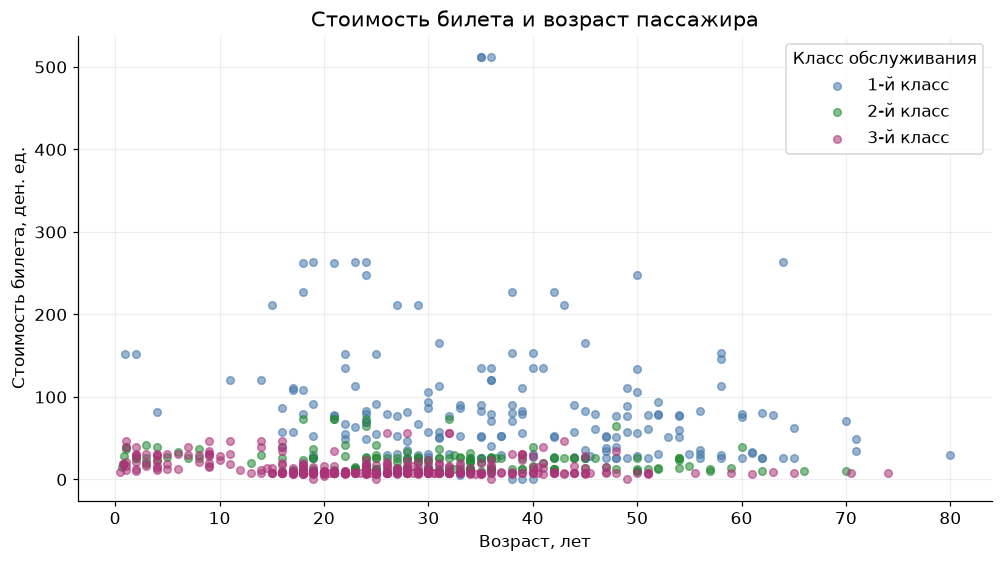

In [26]:
fare_age = passengers.dropna(subset=['Age', 'Fare'])
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
for passenger_class, color in zip([1, 2, 3], class_colors):
    group = fare_age.loc[fare_age['Pclass'] == passenger_class]
    ax.scatter(group['Age'], group['Fare'], s=25, alpha=0.55,
               color=color, label=f'{passenger_class}-й класс')
ax.set(title='Стоимость билета и возраст пассажира',
       xlabel='Возраст, лет', ylabel='Стоимость билета, ден. ед.')
ax.legend(title='Класс обслуживания')
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
plt.show()


4. Постройте box plot отображающий распределение цен на билеты в разных классах

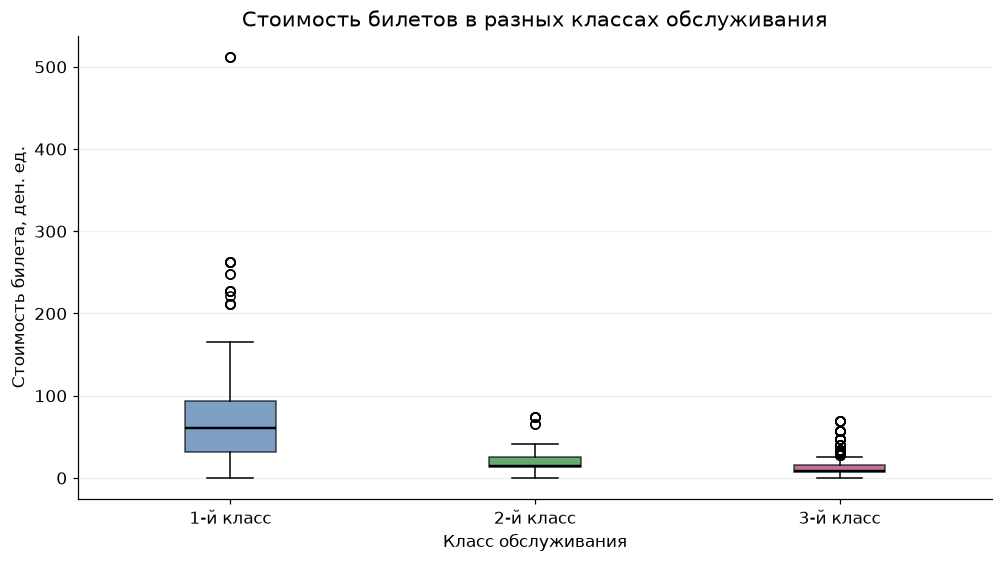

In [27]:
fares_by_class = [
    passengers.loc[passengers['Pclass'] == cls, 'Fare'].dropna()
    for cls in [1, 2, 3]
]
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
boxes = ax.boxplot(fares_by_class, patch_artist=True,
                   medianprops={'color': 'black', 'linewidth': 1.6})
for box, color in zip(boxes['boxes'], class_colors):
    box.set_facecolor(color)
    box.set_alpha(0.7)
ax.set_xticks([1, 2, 3], ['1-й класс', '2-й класс', '3-й класс'])
ax.set(title='Стоимость билетов в разных классах обслуживания',
       xlabel='Класс обслуживания', ylabel='Стоимость билета, ден. ед.')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
plt.show()


5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

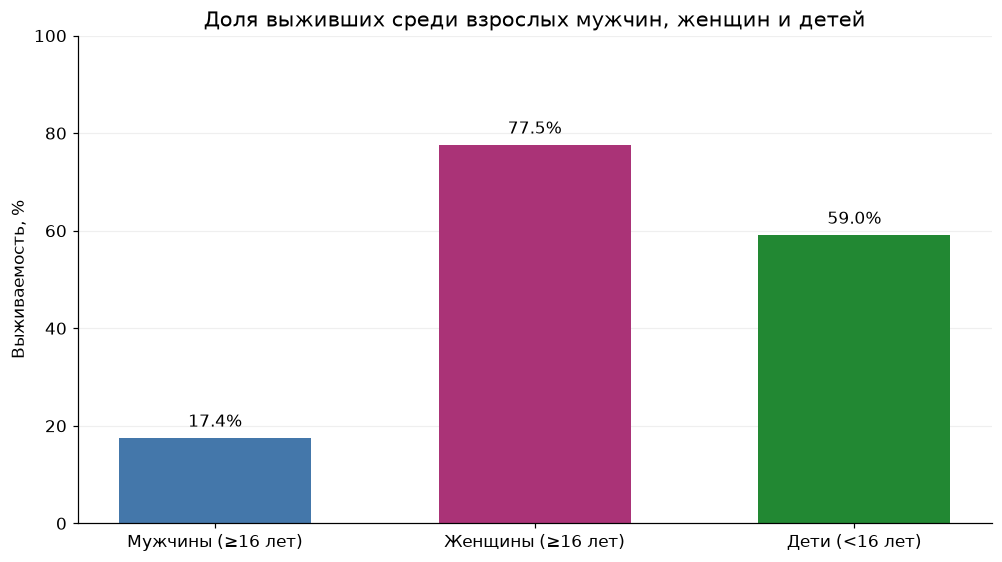

In [28]:
rates = demographic_survival['Выживаемость, %'].to_numpy()
labels = ['Мужчины (≥16 лет)', 'Женщины (≥16 лет)', 'Дети (<16 лет)']
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
bars = ax.bar(labels, rates, color=['#4477AA', '#AA3377', '#228833'], width=0.6)
ax.bar_label(bars, labels=[f'{value:.1f}%' for value in rates], padding=5)
ax.set(title='Доля выживших среди взрослых мужчин, женщин и детей',
       ylabel='Выживаемость, %', ylim=(0, 100))
ax.set_yticks(np.arange(0, 101, 20))
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
plt.show()


6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

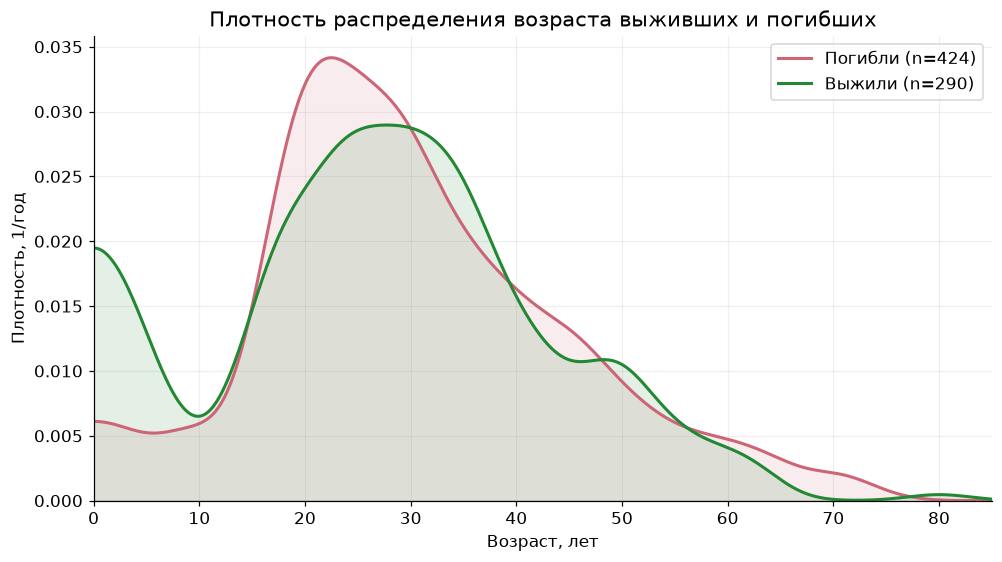

,Известный_возраст,Средний_возраст,Медианный_возраст
Survived,,,
Погибли,424,30.63,28.0
Выжили,290,28.34,28.0


In [29]:
from scipy.stats import gaussian_kde

age_grid = np.linspace(0, 85, 600)
bandwidth_years = 3.0
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
for survived, label, color in [(0, 'Погибли', '#CC6677'), (1, 'Выжили', '#228833')]:
    ages = passengers.loc[passengers['Survived'] == survived, 'Age'].dropna()

    reflected = np.concatenate([ages.to_numpy(), -ages.to_numpy()])
    kde = gaussian_kde(reflected, bw_method=bandwidth_years / reflected.std(ddof=1))
    density = 2 * kde(age_grid)
    ax.plot(age_grid, density, color=color, linewidth=2,
            label=f'{label} (n={len(ages)})')
    ax.fill_between(age_grid, density, color=color, alpha=0.12)
ax.set(title='Плотность распределения возраста выживших и погибших',
       xlabel='Возраст, лет', ylabel='Плотность, 1/год', xlim=(0, 85), ylim=(0, None))
ax.legend()
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
plt.show()

age_outcomes = passengers.groupby('Survived')['Age'].agg(
    Известный_возраст='count', Средний_возраст='mean', Медианный_возраст='median'
).rename(index={0: 'Погибли', 1: 'Выжили'})
display(age_outcomes)


У выживших выше доля маленьких детей, а средний возраст немного ниже,
чем у погибших. В обеих группах преобладают молодые взрослые.
Распределения сильно перекрываются: одного возраста недостаточно
для объяснения исхода.


7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл